<a href="https://colab.research.google.com/github/gyeongee/TIL/blob/main/%EC%A0%81%EC%9D%91%ED%98%95_%ED%95%99%EC%8A%B5%EB%A5%A0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

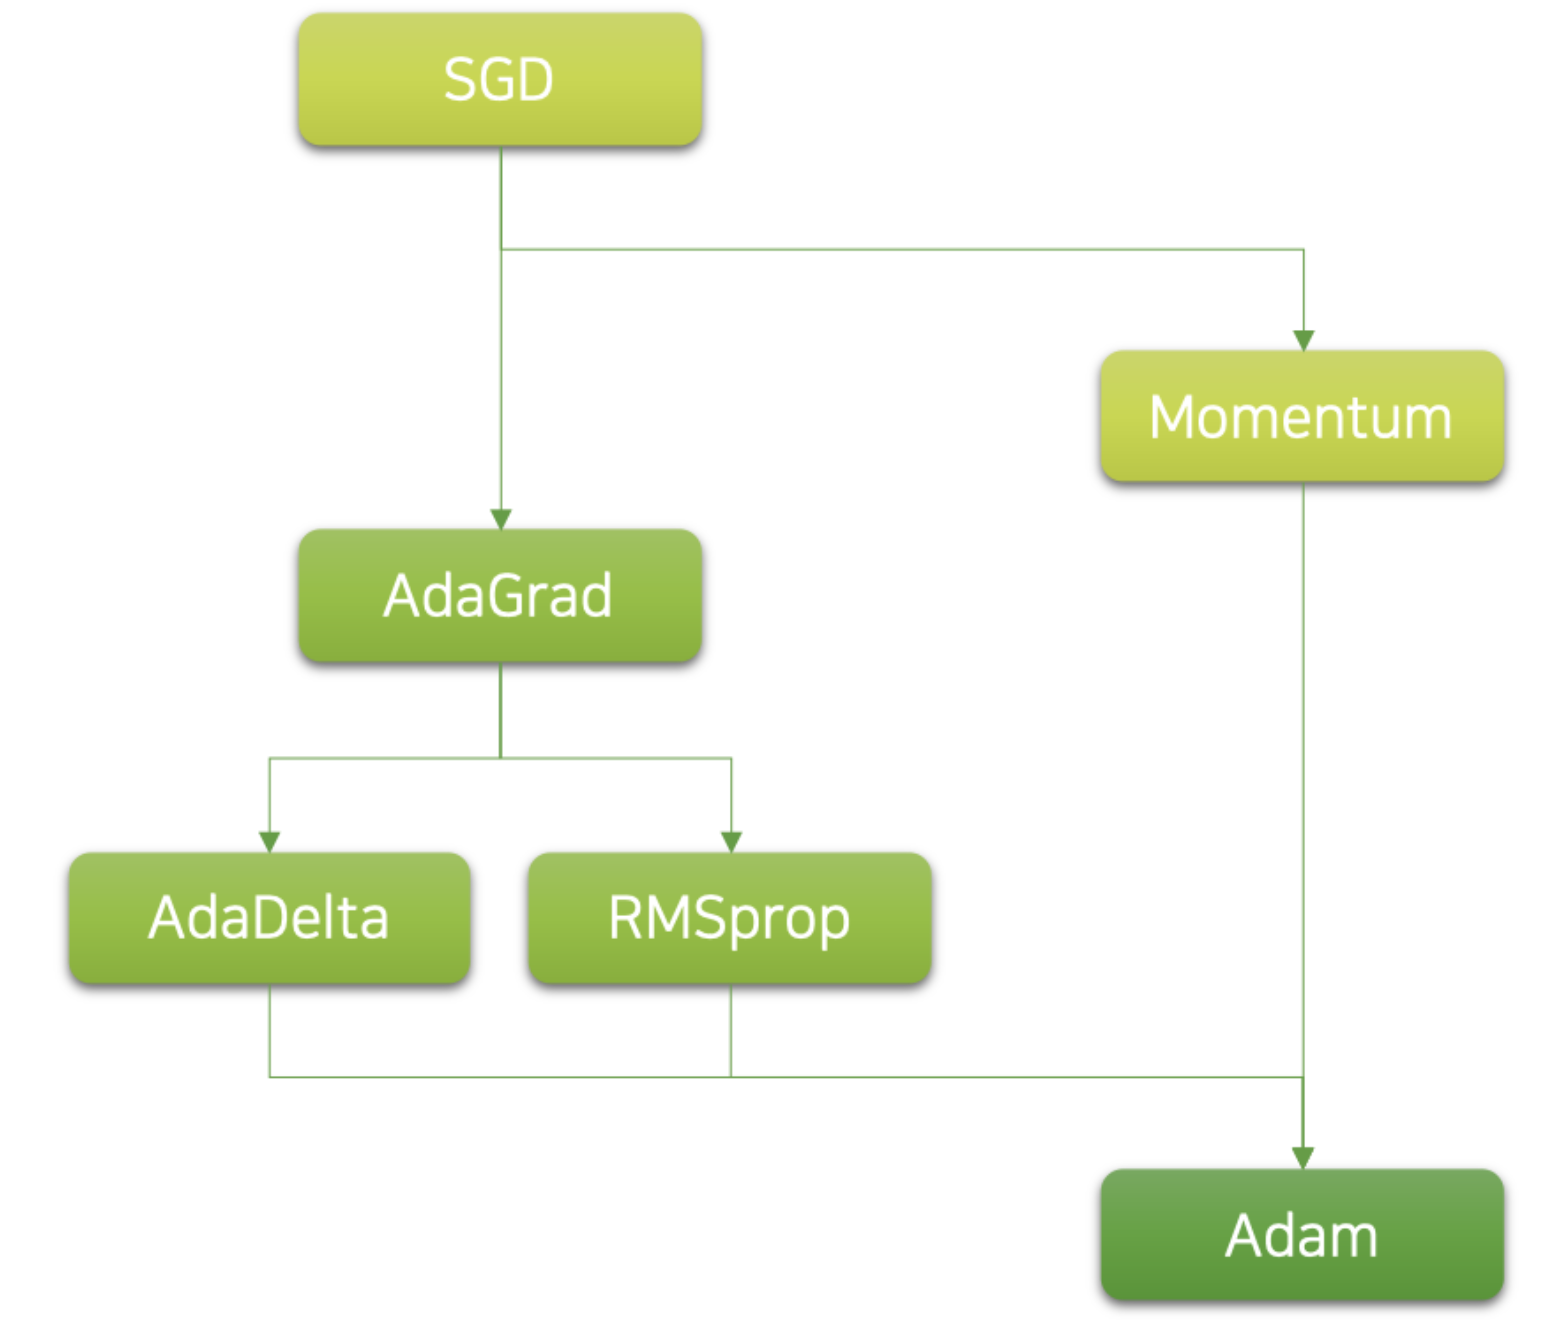

학습률에 따라 학습의 진행 양상이 달라지기 때문에, 적절한 학습률을 설정하는 것이 중요합니다.

특히 학습 초반에는 아직 최적점까지 이동해야 할 거리가 멀기 때문에 큰 학습률을 사용하고, 학습이 진행될수록 학습률을 점차 감소시키는 방식이 효과적입니다. 따라서 학습률을 학습 과정 전체에서 고정하기보다 학습 진행 상황에 따라 동적으로 조절하면 보다 안정적이고 효율적인 학습이 가능합니다.

### 모멘텀

- 지역최소점을 쉽게 탈출할 수 있을 뿐만 아니라 학습 속도를 가속화할 수 있습니다.

- 그래디언트에 노이즈가 많은 상황에서도 가속시켜준다는 점에서 널리 활용되고 있습니다. 하지만, 학습률의 크기에 따라서 최적하 여부가 좌지우지될 수 있습니다.

모멘텀은 시작부터 매번 계산된 그래디언트를 누적하는 형태로 구현됩니다.

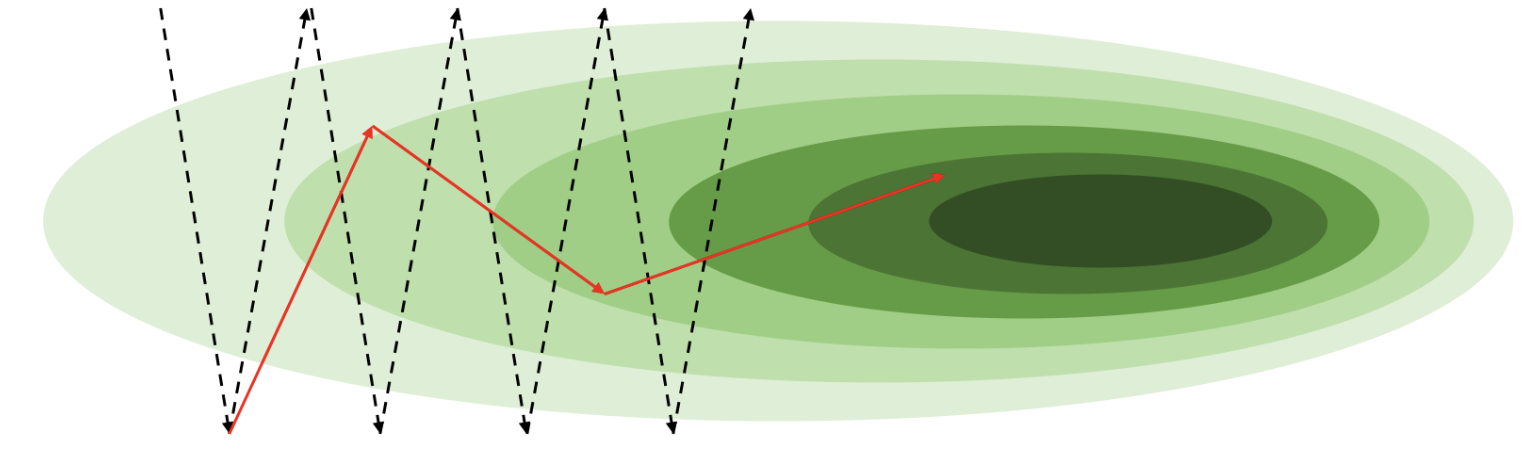

### 적응형 학습률

- 학습률의 설정에 따라 모델이 학습 경향이 매우 달라질 수 있습니다.

- 학습 초기에는 큰 학습률이 선호되고 학습 후반에는 작은 학습률이 선호됩니다.

- 이를 응용하여 각 가중치 파라미터별 학습 진행 정도에 따라 학습률을 다르게 자동 적용할 수 있습니다.

### AdaGrad(아다그래드)
- 가중치 파라미터마다 별도의 학습률을 가집니다.
각 가중치 파라미터의 학습률은 가중치 파라미터가 업데이트될수록 반비례하여 작아지게 됩니다.

- 후반부에 갈수록 0에 가까운 학습률이 되어 그래디언트 $g_t$가 충분히 큰 상황이더라도 학습이 진전되지 못할 수 있습니다.


### Adam optimizer(아담 옵티마이저)
- 모멘템과 적응형 학습률이 복합 적용된 방식이며 가장 널리 쓰이는 알고리즘입니다.
- 여전히 학습률이 수식에 남아있고 오히려 추가적인 하이퍼파리마터가 생겼지만 사실 대부분은 기본(default)값으로 두어도 매우 잘 동작하기 때문에 튜닝할 필요가 거의 없습니다.

Adam optimizier 적용하기

###

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm

In [6]:
from sklearn.datasets import fetch_california_housing
house=fetch_california_housing()

df=pd.DataFrame(data=house.data,columns=house.feature_names)
df['target']=house.target

df.head(3)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521


In [7]:
data=torch.from_numpy(df.values).float()

X = data[:,:-1]
y = data[:,-1:]
print(X.shape,y.shape)

torch.Size([20640, 8]) torch.Size([20640, 1])


Adam optimizer를 사용하기 때문에 학습률을 지정하지 않습니다.

In [17]:
n_epochs=4000
batch_size=256
print_interval=200

In [11]:
model=nn.Sequential(
    nn.Linear(X.size(-1),6),
    nn.LeakyReLU(),
    nn.Linear(6,5),
    nn.LeakyReLU(),
    nn.Linear(5,4),
    nn.LeakyReLU(),
    nn.Linear(4,3),
    nn.LeakyReLU(),
    nn.Linear(3,y.size(-1)),
)

In [15]:
optimizer=optim.Adam(model.parameters())
optimizer

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)

In [18]:
for i in tqdm(range(n_epochs)):
  indices=torch.randperm(X.size(0))
  X_=torch.index_select(X,dim=0,index=indices)
  y_=torch.index_select(y,dim=0,index=indices)

  # |x_i|=(batch_size,input_size)
  X_=X_.split(batch_size,dim=0)
  # |y_i|=(batch_size,output_size)
  y_=y_.split(batch_size,dim=0)

  y_hat=[]
  total_loss=0

  for X_i,y_i in zip(X_,y_):
    y_hat_i=model(X_i)
    loss=F.mse_loss(y_hat_i,y_i)

    optimizer.zero_grad()
    loss.backward()

    optimizer.step()

    total_loss += float(loss)
    y_hat += [y_hat_i]

  total_loss = total_loss / len(X_)
  if (i+1) % print_interval == 0:
    print('Epoch %d: loss=%.4e' % (i+1,total_loss))

y_hat=torch.cat(y_hat,dim=0)
y=torch.cat(y_,dim=0)

  0%|          | 0/4000 [00:00<?, ?it/s]/tmp/ipykernel_2232/4013745379.py:23: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  total_loss += float(loss)
  5%|▌         | 201/4000 [00:30<08:45,  7.22it/s]

Epoch 200: loss=4.7200e-01


 10%|█         | 401/4000 [00:59<07:57,  7.53it/s]

Epoch 400: loss=4.4604e-01


 15%|█▌        | 601/4000 [01:28<07:36,  7.45it/s]

Epoch 600: loss=4.4114e-01


... (30 outputs left out)

 95%|█████████▌| 3801/4000 [09:14<00:36,  5.50it/s]

Epoch 3800: loss=4.1237e-01


100%|██████████| 4000/4000 [09:43<00:00,  6.85it/s]

Epoch 4000: loss=4.1434e-01


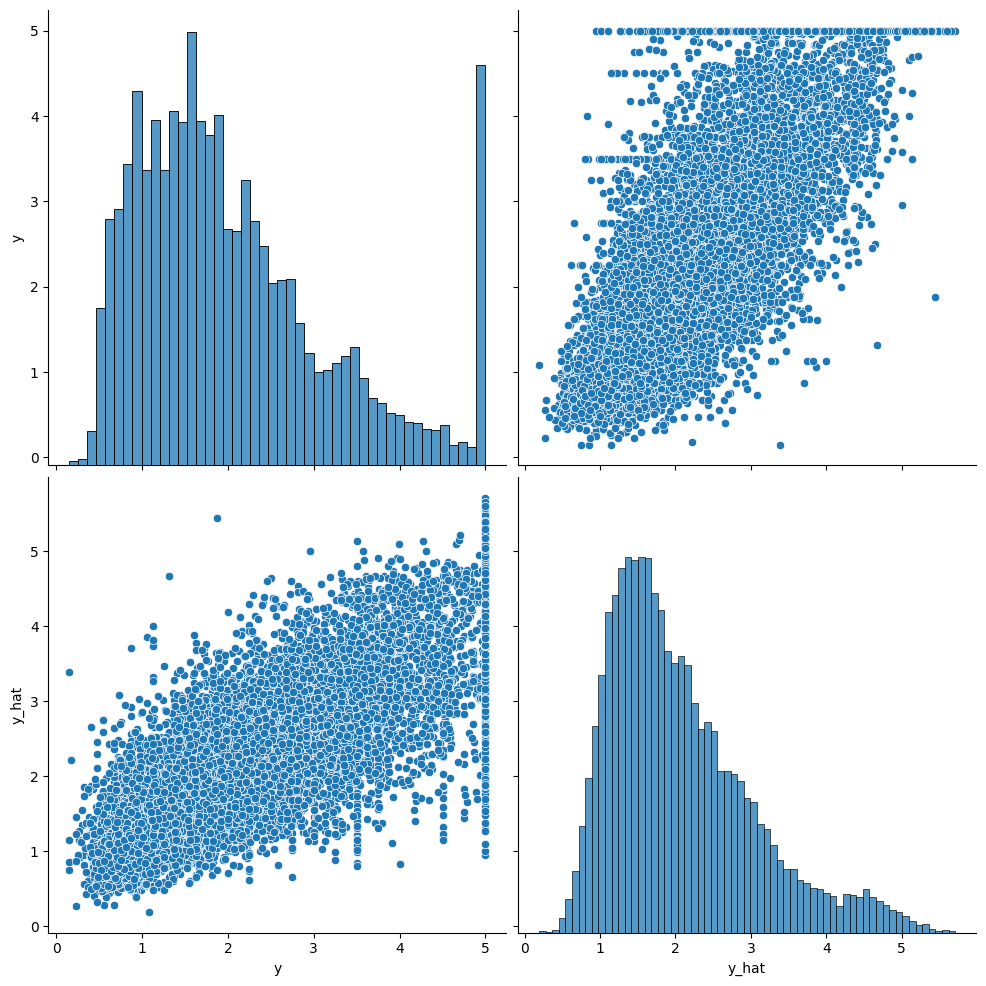

In [21]:
# 결과 시각화
df=pd.DataFrame(torch.cat([y,y_hat],dim=1).detach().numpy(),
             columns=['y','y_hat'])

sns.pairplot(df,height=5)
plt.show()

optimizer를 Adam으로 변경하니 y값과 y_hat의 분포가 비슷함. 하지만 실제 정답 y처럼 튀어나와 있는 부분은 예측이 이루어지지 않은 것을 알 수 있다.